# Why online learners drop out, and what might bring them back

**A learning-analytics case study on the Open University Learning Analytics Dataset (OULAD)**

This notebook walks through the whole project in order: the data, the questions, what the clickstream shows about engagement and scores, where students drop off, the earliest warning sign, two learner personas that explain the pattern with cognitive-load and spacing theory, three interface interventions designed from it, and a simulated before/after of those interventions.

### Key findings at a glance

| | Finding |
|---|---|
| **Frequency beats duration** | In the 14 days before a deadline, mean scores rise from about 70 with no active days to 84 with all 14. Longer sessions help much less and level off around 20 clicks per day. |
| **Drop-off starts early** | Students who end up withdrawing are already disengaging in week 0. Their weekly active share halves from 51% to 24% by week 8, and their median last active week is 7. Students who fail fade more slowly (median last active week 14). |
| **Earliest warning** | Students with zero active days in weeks 0 to 3 pass only 5% of the time. One active day lifts that to 24%. |
| **Two personas** | Jordan, the early withdrawer (overload, cognitive load), and Sam, the gradual fader (lost rhythm, spacing). |
| **Three interventions** | C2 "One small thing", C6 "Deadline runway", C7 "Welcome back". |
| **Simulated effect** | ⚠️ *Illustrative only.* Under modest assumed effect sizes, the drop-off curves flatten by a few points. This is a what-if, not evidence. |

### How to run this notebook

1. Put the seven OULAD CSVs (including the ~450 MB `studentVle.csv`) in a `data/` folder next to this notebook, or set the `OULAD_DATA_DIR` environment variable to the folder that holds them. See `data/README.md`.
2. `pip install -r requirements.txt`
3. Run all cells. The full pipeline takes well under a minute on a laptop and needs about 3 GB of memory.

The heavy lifting lives in three small modules so that this notebook stays readable:

- `oulad_clean.py` loads, cleans and merges the tables,
- `engagement_over_time.py` builds the weekly engagement panel, the per-assessment windows, the drop-off statistics and the charts,
- `simulate_intervention.py` runs the illustrative before/after simulation.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import oulad_clean as oc
import engagement_over_time as eot

pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
FIG_DIR = oc.HERE / "figures"
FIG_DIR.mkdir(exist_ok=True)
RAW = ["courses", "assessments", "studentInfo", "studentRegistration",
       "studentAssessment", "vle", "studentVle"]
missing = [t for t in RAW if not (oc.DATA_DIR / f"{t}.csv").exists()]
assert not missing, f"Missing OULAD files in {oc.DATA_DIR}: {missing}. See data/README.md."
print(f"Found all {len(RAW)} OULAD tables.")

Found all 7 OULAD tables.


## 1. The data and the questions

[OULAD](https://analyse.kmi.open.ac.uk/open_dataset) is an anonymised public dataset from the Open University (UK): 32,593 enrolments of 28,785 students on 7 modules, across 22 module runs ("presentations") in 2013 and 2014. It has seven tables:

| Table | What one row is |
|---|---|
| `courses.csv` | a module presentation and its length in days |
| `assessments.csv` | an assessment: tutor-marked (TMA), computer-marked (CMA) or exam, its due day and weight |
| `studentInfo.csv` | an enrolment: demographics, credits studied, previous attempts and **final result** (Distinction, Pass, Fail, Withdrawn) |
| `studentRegistration.csv` | registration and (if any) unregistration day for an enrolment |
| `studentAssessment.csv` | a submitted assessment and its score (0 to 100) |
| `vle.csv` | a page or resource on the virtual learning environment (VLE) |
| `studentVle.csv` | **the clickstream**: clicks by a student on a VLE resource on a given day (10.6 million rows) |

All dates are day offsets from the start of the module, so day 0 is the first day and negative days are before the start.

**Questions asked**

1. How does engagement relate to assessment scores? Does it matter more *how often* students show up or *how long* they stay?
2. Is there a drop-off point, a time when struggling students stop engaging?
3. Is there an early-warning signal that could trigger help in time?
4. What learning-science mechanisms could explain the pattern, and what interventions follow from them?

In [2]:
sv = oc.load_student_vle()          # the 10.6M-row clickstream, loaded once and reused
tables = oc.build_all(sv=sv)
features = tables["student_features"]
student_assessments = tables["student_assessments"]

print(f"Clickstream rows:  {len(sv):,}")
print(f"Enrolments:        {len(features):,}  ({features['id_student'].nunique():,} distinct students)")
print(f"Module runs:       {features.groupby(['code_module', 'code_presentation']).ngroups}")
print()
outcomes = features["final_result"].value_counts().reindex(["Distinction", "Pass", "Fail", "Withdrawn"])
pd.DataFrame({"enrolments": outcomes, "share": outcomes / outcomes.sum()})

Clickstream rows:  10,655,280
Enrolments:        32,593  (28,785 distinct students)
Module runs:       22



,enrolments,share
final_result,,
Distinction,3024,0.093
Pass,12361,0.379
Fail,7052,0.216
Withdrawn,10156,0.312


Almost a third of enrolments end in withdrawal and another fifth in a fail, so disengagement is the norm rather than the exception. That is the problem this case study is about.

## 2. Cleaning and merging

`oc.build_all()` produces one row per **enrolment** (module run × student), not per student, because many students took more than one module. Each row joins demographics and final result, registration dates, clickstream totals and assessment results (58 columns).

Cleaning decisions worth knowing about:

- **IMD band.** One deprivation band is written `10-20` instead of `10-20%`; it is relabelled.
- **Exam dates.** Some exams have no date. OULAD's documentation says the final exam is at the end of the presentation, so they get the presentation's last day.
- **No clickstream.** About 3,400 enrolments have no VLE activity at all. Their click counts are set to 0 (not left missing) and `has_vle_activity` is False, because "never logged in" is meaningful.
- **Exam scores are sparse.** Only about 5,000 enrolments have one, so coursework scores (TMA and CMA) are used as the measure of accuracy.
- **Banked results** carry a submission date from an earlier attempt, so lateness is left undefined for them.
- **Module GGG** gives its coursework zero weight, so its weighted coursework score is blank; use `mean_coursework_score` there.

A quick integrity check: the merged table must account for every click in the raw file.

In [3]:
assert features["total_clicks"].sum() == sv["sum_click"].sum()
print(f"Total clicks match the raw file: {sv['sum_click'].sum():,}")
print(f"Enrolments with no VLE activity: {(~features['has_vle_activity']).sum():,}")

features.groupby("final_result", observed=True)[
    ["total_clicks", "n_active_days", "clicks_per_active_day", "mean_coursework_score"]
].median().reindex(["Distinction", "Pass", "Fail", "Withdrawn"]).round(1)

Total clicks match the raw file: 39,605,099
Enrolments with no VLE activity: 3,365


,total_clicks,n_active_days,clicks_per_active_day,mean_coursework_score
final_result,,,,
Distinction,1896.0,103.0,19.4,89.3
Pass,1343.0,78.0,17.8,78.2
Fail,317.0,22.0,14.6,66.2
Withdrawn,89.0,7.0,14.4,68.0


Even this crude summary shows the gradient: the median Withdrawn enrolment has about 90 clicks over the whole module, against roughly 1,300 for Pass and 1,900 for Distinction. The rest of the notebook asks *when* and *in what form* that gap opens.

## 3. Defining engagement over time

OULAD logs clicks **per day**, not per session, and has no timestamps. So the analysis uses two proxies:

- **Frequency:** an *active day* is a day with at least one click. This stands in for a study session.
- **Duration / intensity:** *clicks per active day* stands in for session length.

Two derived tables are built from the clickstream:

- **Weekly panel** (`weekly_panel`): one row per enrolment per course week, from week −2 to the end of the module, *including weeks with no activity*. Filling in the zeros matters: a student who stops logging in should count as inactive, not disappear from the denominator.
- **Pre-deadline windows** (`assessment_engagement`): for every scored, non-banked coursework submission, the clicks and active days in the **14 days before the deadline**. This lines engagement up with the score it could plausibly have influenced.

In [4]:
panel = eot.weekly_panel(sv, features)
ae = eot.assessment_engagement(sv, student_assessments)
do, enrol = eot.drop_off(panel, features)

print(f"Weekly panel:          {len(panel):,} enrolment-weeks")
print(f"Pre-deadline windows:  {len(ae):,} coursework submissions")
ae[["window_active_days", "window_clicks", "window_clicks_per_active_day", "score"]].describe().round(1)

Weekly panel:          1,277,763 enrolment-weeks
Pre-deadline windows:  166,872 coursework submissions


,window_active_days,window_clicks,window_clicks_per_active_day,score
count,166872.0,166872.0,158746.0,166872.0
mean,5.4,156.4,27.5,76.1
std,3.5,209.5,34.4,18.7
min,0.0,0.0,1.0,0.0
25%,3.0,31.0,10.1,66.0
50%,5.0,84.0,17.9,80.0
75%,8.0,196.0,31.8,90.0
max,14.0,7028.0,1298.0,100.0


## 4. Engagement vs. scores: how often beats how long

For each coursework submission, compare the score with (a) how many of the 14 days before the deadline the student was active, and (b) how many clicks they made per active day.

In [5]:
by_days = (ae.groupby(ae["window_active_days"].clip(upper=14).astype(int))["score"]
             .agg(mean_score="mean", submissions="size"))
by_days.T.round(1)

window_active_days,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
mean_score,70.5,71.3,72.3,73.9,74.9,76.4,77.2,78.2,79.0,79.5,80.2,80.8,81.9,82.6,83.9
submissions,8126.0,13602.0,17553.0,18950.0,18568.0,16906.0,15092.0,13185.0,11312.0,9245.0,7385.0,5747.0,4538.0,3292.0,3371.0


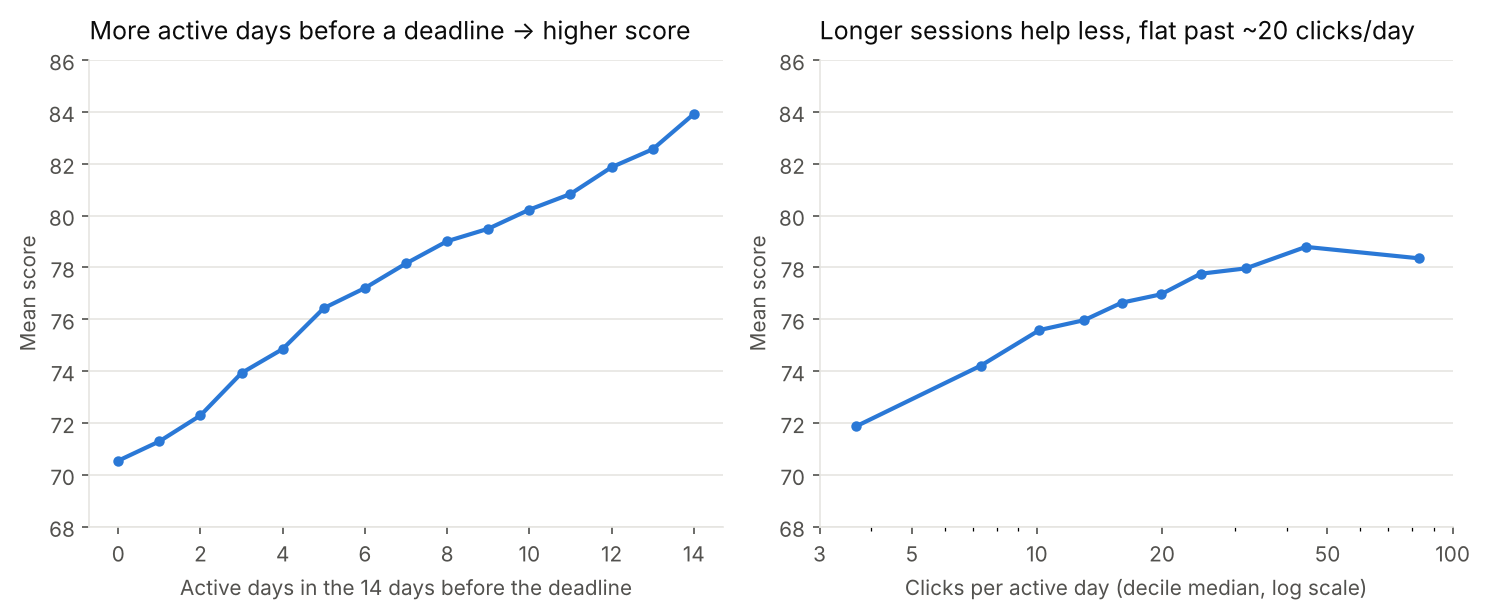

In [6]:
fig = eot.plot_score_vs_engagement(ae)
fig.savefig(FIG_DIR / "score_vs_engagement.png")
plt.show()

The left panel climbs steadily: from about **70 with no active days to 84 with all 14**, roughly one point per extra day, with no plateau. The right panel rises at first and then **levels off at about 20 clicks per active day** (score around 78). Beyond that, a longer session buys almost nothing.

Correlation alone could be driven by *who* the students are (strong students both log in more and score higher). To separate that out, the cell below also computes a **within-student** correlation: each submission is ranked within its assessment (so module difficulty doesn't leak in), and each enrolment's own average is subtracted, so the question becomes "does *this* student score better on assessments where *they* showed up more?"

In [7]:
corr = pd.DataFrame({
    "overall (Spearman)": [
        ae[["window_active_days", "score"]].corr("spearman").iloc[0, 1],
        ae[["window_clicks_per_active_day", "score"]].corr("spearman").iloc[0, 1],
    ],
    "within-student": [
        eot.within_student_corr(ae, "window_active_days"),
        eot.within_student_corr(ae, "window_clicks_per_active_day"),
    ],
}, index=["active days (frequency)", "clicks per active day (duration)"])
corr.round(3)

,overall (Spearman),within-student
active days (frequency),0.170,0.092
clicks per active day (duration),0.084,0.036


**Takeaway.** Frequency is the stronger signal both across students (ρ ≈ 0.17 vs 0.08) and within the same student (≈ 0.09 vs 0.04). About half of the frequency effect disappears within-student, so part of it is who the student is, but the half that remains says that the same person tends to do better when they spread their study across more days. These are modest effects, and clicks are a proxy for study, not a measure of learning.

## 5. The drop-off point

Next, the share of each outcome group that is active (at least one click) in each course week.

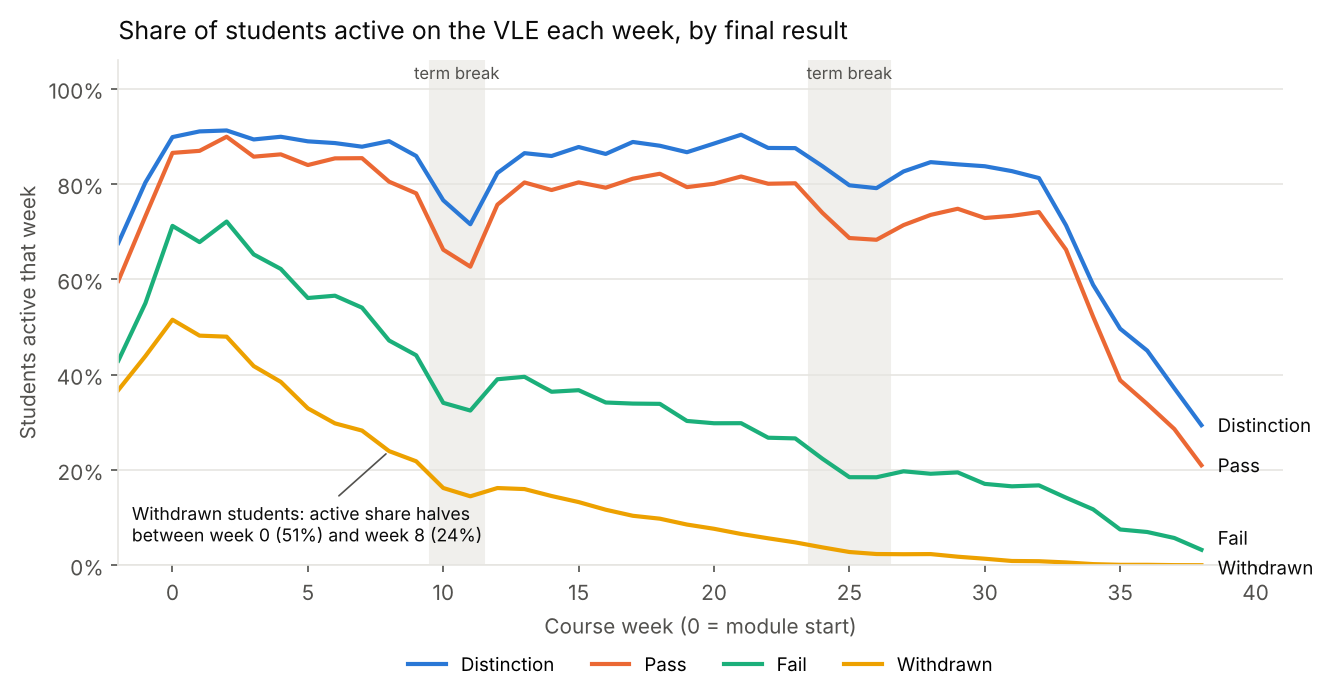

final_result,Distinction,Pass,Fail,Withdrawn
week,,,,
0,90%,86%,71%,51%
4,90%,86%,62%,38%
8,89%,80%,47%,24%
14,86%,79%,36%,15%
20,88%,80%,30%,8%
30,84%,73%,17%,1%


In [8]:
fig = eot.plot_engagement_by_week(do)
fig.savefig(FIG_DIR / "engagement_by_week.png")
plt.show()

order = ["Distinction", "Pass", "Fail", "Withdrawn"]
do["active_share"].loc[[0, 4, 8, 14, 20, 30], order].style.format("{:.0%}")

Three things stand out:

- **Withdrawers are disengaging from the very first week.** Only about half are active in week 0, and the share halves again to 24% by week 8. There is no healthy start followed by a crash; the decline begins at day 0.
- **Students who fail fade gradually.** They start at about 71% active and lose a few points a week, ending under 20% by week 30.
- **Pass and Distinction students stay at 80 to 90%.** The dips around weeks 10 to 11 and 24 to 26 hit *every* group at once, so they are term breaks (Christmas and Easter), not drop-off.

To put a date on individual drop-off, take each enrolment's **last active week**, and count it as "dropped off" if activity stops more than four weeks before the module ends.

In [9]:
summary = pd.DataFrame({
    "share who drop off": do["dropoff_by_result"],
    "median last active week": do["last_week_hist"]["50%"],
    "IQR (25%)": do["last_week_hist"]["25%"],
    "IQR (75%)": do["last_week_hist"]["75%"],
}).reindex(order)
display(summary.round(2))

lag = do["withdraw_lag_days"]
print(f"Withdrawers: median gap between last active week and formal unregistration = {lag['50%']:.0f} days")

,share who drop off,median last active week,IQR (25%),IQR (75%)
final_result,,,,
Distinction,0.08,32.0,31.0,33.0
Pass,0.12,32.0,30.0,33.0
Fail,0.74,14.0,6.0,23.0
Withdrawn,0.99,7.0,2.0,15.0


Withdrawers: median gap between last active week and formal unregistration = 9 days


Almost every withdrawer (99%) and three quarters of the students who fail go quiet well before the end. The difference is *when*: the median withdrawer's last active week is **week 7**, the median failing student's is **week 14**. Withdrawers then formally unregister about **9 days** after their last activity, which is a short but real window in which someone could notice.

So there isn't one drop-off point but two drop-off *shapes*: an early exit and a slow fade. That distinction drives everything that follows.

## 6. The early-warning signal

If drop-off starts in week 0, the warning has to come early too. The simplest candidate: how many days was the student active in the **first four weeks** (weeks 0 to 3, so 0 to 28 days)?

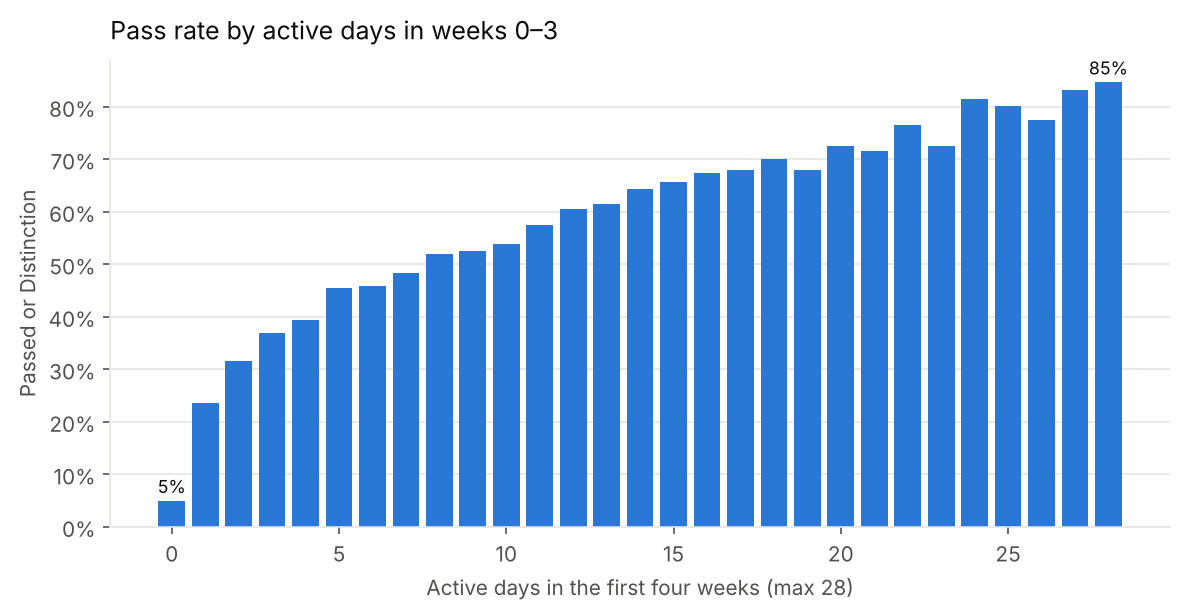

,pass rate,enrolments
early_active_days,,
0,5%,"4,707"
1,24%,"1,443"
2,32%,"1,412"
5,45%,"1,653"
10,54%,"1,416"
20,73%,626
28,85%,345


In [10]:
fig = eot.plot_pass_by_early_activity(do)
fig.savefig(FIG_DIR / "pass_by_early_activity.png")
plt.show()

p = do["pass_by_early_days"]
p.loc[[0, 1, 2, 5, 10, 20, 28]].rename(columns={"mean": "pass rate", "size": "enrolments"}).style.format(
    {"pass rate": "{:.0%}", "enrolments": "{:,}"})

**Zero active days in weeks 0 to 3 is the clearest red flag:** those 4,707 enrolments pass only about 5% of the time. Going from zero to *one* active day is the single biggest jump on the chart (to about 24%). After that there is no sharp threshold; each extra active day adds roughly 2 points of pass rate.

Who are these zero-activity students? The persona work assumed most of them are withdrawers; the cell below checks.

In [11]:
zero = enrol[enrol["early_active_days"].fillna(0) == 0]
print(f"{len(zero):,} enrolments with no activity in weeks 0-3")
zero["final_result"].value_counts(normalize=True).reindex(order).to_frame("share").style.format("{:.0%}")

4,707 enrolments with no activity in weeks 0-3


,share
final_result,
Distinction,1%
Pass,4%
Fail,15%
Withdrawn,80%


Confirmed: about 80% of them end up withdrawing, and most of the rest fail.

How early can engagement tell eventual passers from everyone else? The table below gives the AUC (0.5 = coin flip, 1 = perfect) of *cumulative* active days and clicks up to each week, among students still registered that week.

In [12]:
do["auc_by_week"].loc[[0, 2, 4, 8, 14, 20]].round(3)

,n,auc_cum_clicks,auc_cum_active_days
week,,,
0,29915,0.672,0.660
2,28128,0.664,0.667
4,27553,0.667,0.676
8,26532,0.687,0.704
14,25358,0.715,0.736
20,24294,0.755,0.777


Even at week 0 the signal is well above chance (AUC ≈ 0.66), and it improves steadily, with active days overtaking raw clicks from about week 2. Again, *frequency* carries more information than *volume*.

## 7. Two personas: Jordan and Sam

The two drop-off shapes suggest two different learners, not one "disengaged student". The personas below (full write-up: [Disengaged learner personas](https://claude.ai/artifact/Bpf7mkqHed8Bw1jhxdhHAW)) combine the behavioural findings above with demographic skews from `studentInfo.csv` and `studentRegistration.csv`. Names and quotes are invented; the numbers are not.

In [13]:
f = features.copy()
f["group"] = f["final_result"].astype(str).map(
    {"Withdrawn": "Withdrawn (Jordan)", "Fail": "Fail (Sam)", "Pass": "Pass/Distinction", "Distinction": "Pass/Distinction"})
below_a = ["No Formal quals", "Lower Than A Level"]
skews = f.groupby("group").agg(
    enrolments=("id_student", "size"),
    under_35=("age_band", lambda s: (s == "0-35").mean()),
    below_A_level=("highest_education", lambda s: s.isin(below_a).mean()),
    credits_120_plus=("studied_credits", lambda s: (s >= 120).mean()),
    repeat_attempt=("num_of_prev_attempts", lambda s: (s > 0).mean()),
    most_deprived_20pct=("imd_band", lambda s: s.isin(["0-10%", "10-20%"]).mean()),
    disability=("disability", lambda s: (s == "Y").mean()),
    median_credits=("studied_credits", "median"),
).loc[["Withdrawn (Jordan)", "Fail (Sam)", "Pass/Distinction"]]
fmt = {c: "{:.0%}" for c in skews.columns if c not in ("enrolments", "median_credits")}
display(skews.style.format({**fmt, "enrolments": "{:,}", "median_credits": "{:.0f}"}))

w = f[f["final_result"] == "Withdrawn"]
print(f"Withdrawers who unregister before day 0: {(w['date_unregistration'] < 0).mean():.0%}")
print(f"Withdrawers gone by day 28:              {(w['date_unregistration'] <= 28).mean():.0%}")

,enrolments,under_35,below_A_level,credits_120_plus,repeat_attempt,most_deprived_20pct,disability,median_credits
group,,,,,,,,
Withdrawn (Jordan),"10,156",73%,47%,36%,14%,24%,12%,60
Fail (Sam),"7,052",74%,50%,23%,19%,26%,10%,60
Pass/Distinction,"15,385",67%,34%,21%,9%,16%,8%,60


Withdrawers who unregister before day 0: 26%
Withdrawers gone by day 28:              50%


### Persona A: Jordan, the early withdrawer

> *"I signed up for too much. I never really got started, and by the time I looked properly I was already behind."*

- **Behaviour (data):** only about half active in week 0, falling to 24% by week 8; last active around week 7, then unregisters about 9 days later. Makes up 80% of the students with no activity in weeks 0 to 3.
- **Skews (data):** much more likely to carry **120+ credits** at once; more often below A-level entry. About a quarter unregister before the module even starts, and half are gone by day 28.
- **Design moment:** the first four weeks, ideally before day 0. The aim is a first few active days, not long sessions.

### Persona B: Sam, the gradual fader

> *"I'm still doing it, just not as much as I should. I'll catch up before the exam."*

- **Behaviour (data):** starts active, then shows up on fewer days each week; last active around week 14 but stays registered and fails. Few active days in the 14 days before deadlines, where scores fall from 84 to about 70.
- **Skews (data):** normal study load (60 credits median), so overload is not the story. The group most likely to have entered below A level and the most likely to be on a **repeat attempt**.
- **Design moment:** a steady weekly rhythm mid-course, especially the two weeks before each assessment and the return from each term break.

### Why it happens: cognitive load and spacing

The data fits two well-established learning-science mechanisms. It agrees with both but does not test either directly.

| Data pattern | Mechanism | How it explains the pattern | Persona |
|---|---|---|---|
| Scores rise with active days (70 → 84) more than with clicks per day | **Spacing effect:** practice spread over many sessions is retained better than the same amount massed together (Ebbinghaus 1885; Cepeda et al. 2006) | Each return visit is a spaced retrieval, so more days means more chances to consolidate | Sam |
| Scores level off at ~20 clicks per day | **Limited working memory** (Sweller 1988): long sessions add load faster than they add learning | Extra clicks in one sitting are effectively massed study, with diminishing returns | Sam |
| Gradual fade, then little activity before deadlines | **Massed practice** (cramming) feels efficient but produces weaker, shorter-lived learning (Kornell & Bjork 2008) | Once behind, Sam swaps a steady rhythm for bursts and loses the spacing benefit | Sam |
| Withdrawers carry 120+ credits and disengage from week 0 | **Cognitive load:** intrinsic load of new material plus extraneous load of juggling several modules exceeds capacity | Overload shows up before learning starts, so the cheapest exit is never starting | Jordan |
| Below-A-level entrants over-represented in both groups | **Prior knowledge** sets intrinsic load; the same material is heavier for novices (Kalyuga et al. 2003) | Fewer existing schemas means each session costs more effort | Both |

**Design implications.** For Sam, design for *frequency, not duration*: short spaced tasks across the week and a pre-deadline plan spread over the 14-day window. For Jordan, *cut load at the start*: fewer choices in week 1 and worked examples before open tasks. For both, chunk content so a missed day costs little to recover.

*Citations are standard references and should be checked before use in a formal write-up.*

## 8. Three interventions: C2, C6 and C7

Eight screen concepts were sketched from these findings, each tied to a trigger in the data and to a persona. Three were taken forward to clickable prototypes because they are cheap to build and aim squarely at the two drop-off shapes. One rule applies to all of them: **don't fire nudges in term-break weeks** (10 to 11 and 24 to 26), since every group dips then.

| | C2 "One small thing" | C6 "Deadline runway" | C7 "Welcome back" |
|---|---|---|---|
| **Persona** | Jordan | Sam | Sam |
| **Trigger** | Module has started and the learner has 0 active days. Replaces the dashboard on first login. | 14 days before an assessment, with fewer than ~4 active days in the previous 14. | First login after a term break (week 11 or 26), or no activity 3+ days after a break ends. |
| **Screen** | One task, one button, under 10 minutes (a worked example). No module map, no backlog. A small "see the full module" link. | Splits the assignment into 15-minute daily pieces across the window. Only today's piece has a button; missed days roll forward without turning red. | Hides the backlog. One-line recap of where Sam left off, one task for this week, and the next deadline. Backlog is opt-in. |
| **Mechanism** | Fewer choices cuts extraneous load; the goal is a *first active day*, not a long session. | Swaps massed cramming for spaced work. | Lowers the cost of re-entry; seeing the pile-up is what makes Sam avoid checking. |
| **Evidence it targets** | 0 active days in weeks 0–3 → 5% pass rate; 0 → 1 day is the biggest jump. | Scores rise from ~70 to 84 with active days in the 14-day window. | Deadlines bunch after breaks; Sam is often on a repeat attempt. |
| **How to measure** | Share reaching 1, then 3, active days by end of week 3, vs a holdout. | Active days in the window and assessment score, vs a holdout. | Days to first activity after the break, and active days in the next two weeks. |
| **Risk** | Hides the bigger picture. | Needs module-specific content to split work. | All groups dip after breaks, so show it only to learners who haven't come back. |

## 9. Simulated before/after (⚠️ illustrative, not evidence)

> **Read this section as a what-if, not a result.** No intervention was run. The "after" curves come from a simple model with **assumed** effect sizes. Change the assumptions and the chart changes. Its purpose is to show the *shape* of the change these designs are aiming for and which numbers a real pilot should measure.

**How the simulation works** (`simulate_intervention.py`):

- **Baseline.** The weekly share-active curve of each outcome group (Section 5) is split into two parts: the share of learners still "engaged" (which only falls, and whose week-to-week drop is the dropout hazard), and the chance an engaged learner is active that week (which captures term-break dips). The simulation script was written before the clickstream was available in the project folder, so its baseline curves are transcribed from the Section 5 chart. The check below compares them with the real curves computed above; they agree within about half a percentage point every week.
- **Learners.** 32,593 simulated learners, matching the real group sizes. Each keeps the same random draws before and after, so "after" is *the same learner* with the intervention.
- **Interventions.** Inside its window, and only for learners it reaches, each intervention cuts the dropout hazard and nudges up the chance of being active.

| Intervention | Window | Reach (assumed) | Effect (assumed) |
|---|---|---|---|
| C2 One small thing | weeks 0–3 | 60% of withdrawers, 50% of fails | dropout hazard −40%, activity +10% |
| C6 Deadline runway | 2 weeks before each TMA | 40% / 50% | hazard −25%, activity +8% |
| C7 Welcome back | weeks 10–13, 24–27 | 40% / 50%, 30% of Pass/Distinction | hazard −35%, recovers 30% of the break dip |

In [14]:
import simulate_intervention as sim

# How close is the simulation's transcribed baseline to the real curves from Section 5?
real = do["active_share"].reindex(sim.WEEKS)
gap = pd.Series({g: np.abs(real[g].values - sim.BASE[g]).max() for g in sim.GROUPS})
print("Largest weekly gap between transcribed and real share active (percentage points):")
print((gap * 100).round(1).to_string())

Largest weekly gap between transcribed and real share active (percentage points):
Withdrawn      0.3
Fail           0.3
Pass           0.4
Distinction    0.5


Assessment weeks used for the C6 runway: [3, 7, 14, 18, 23, 28]


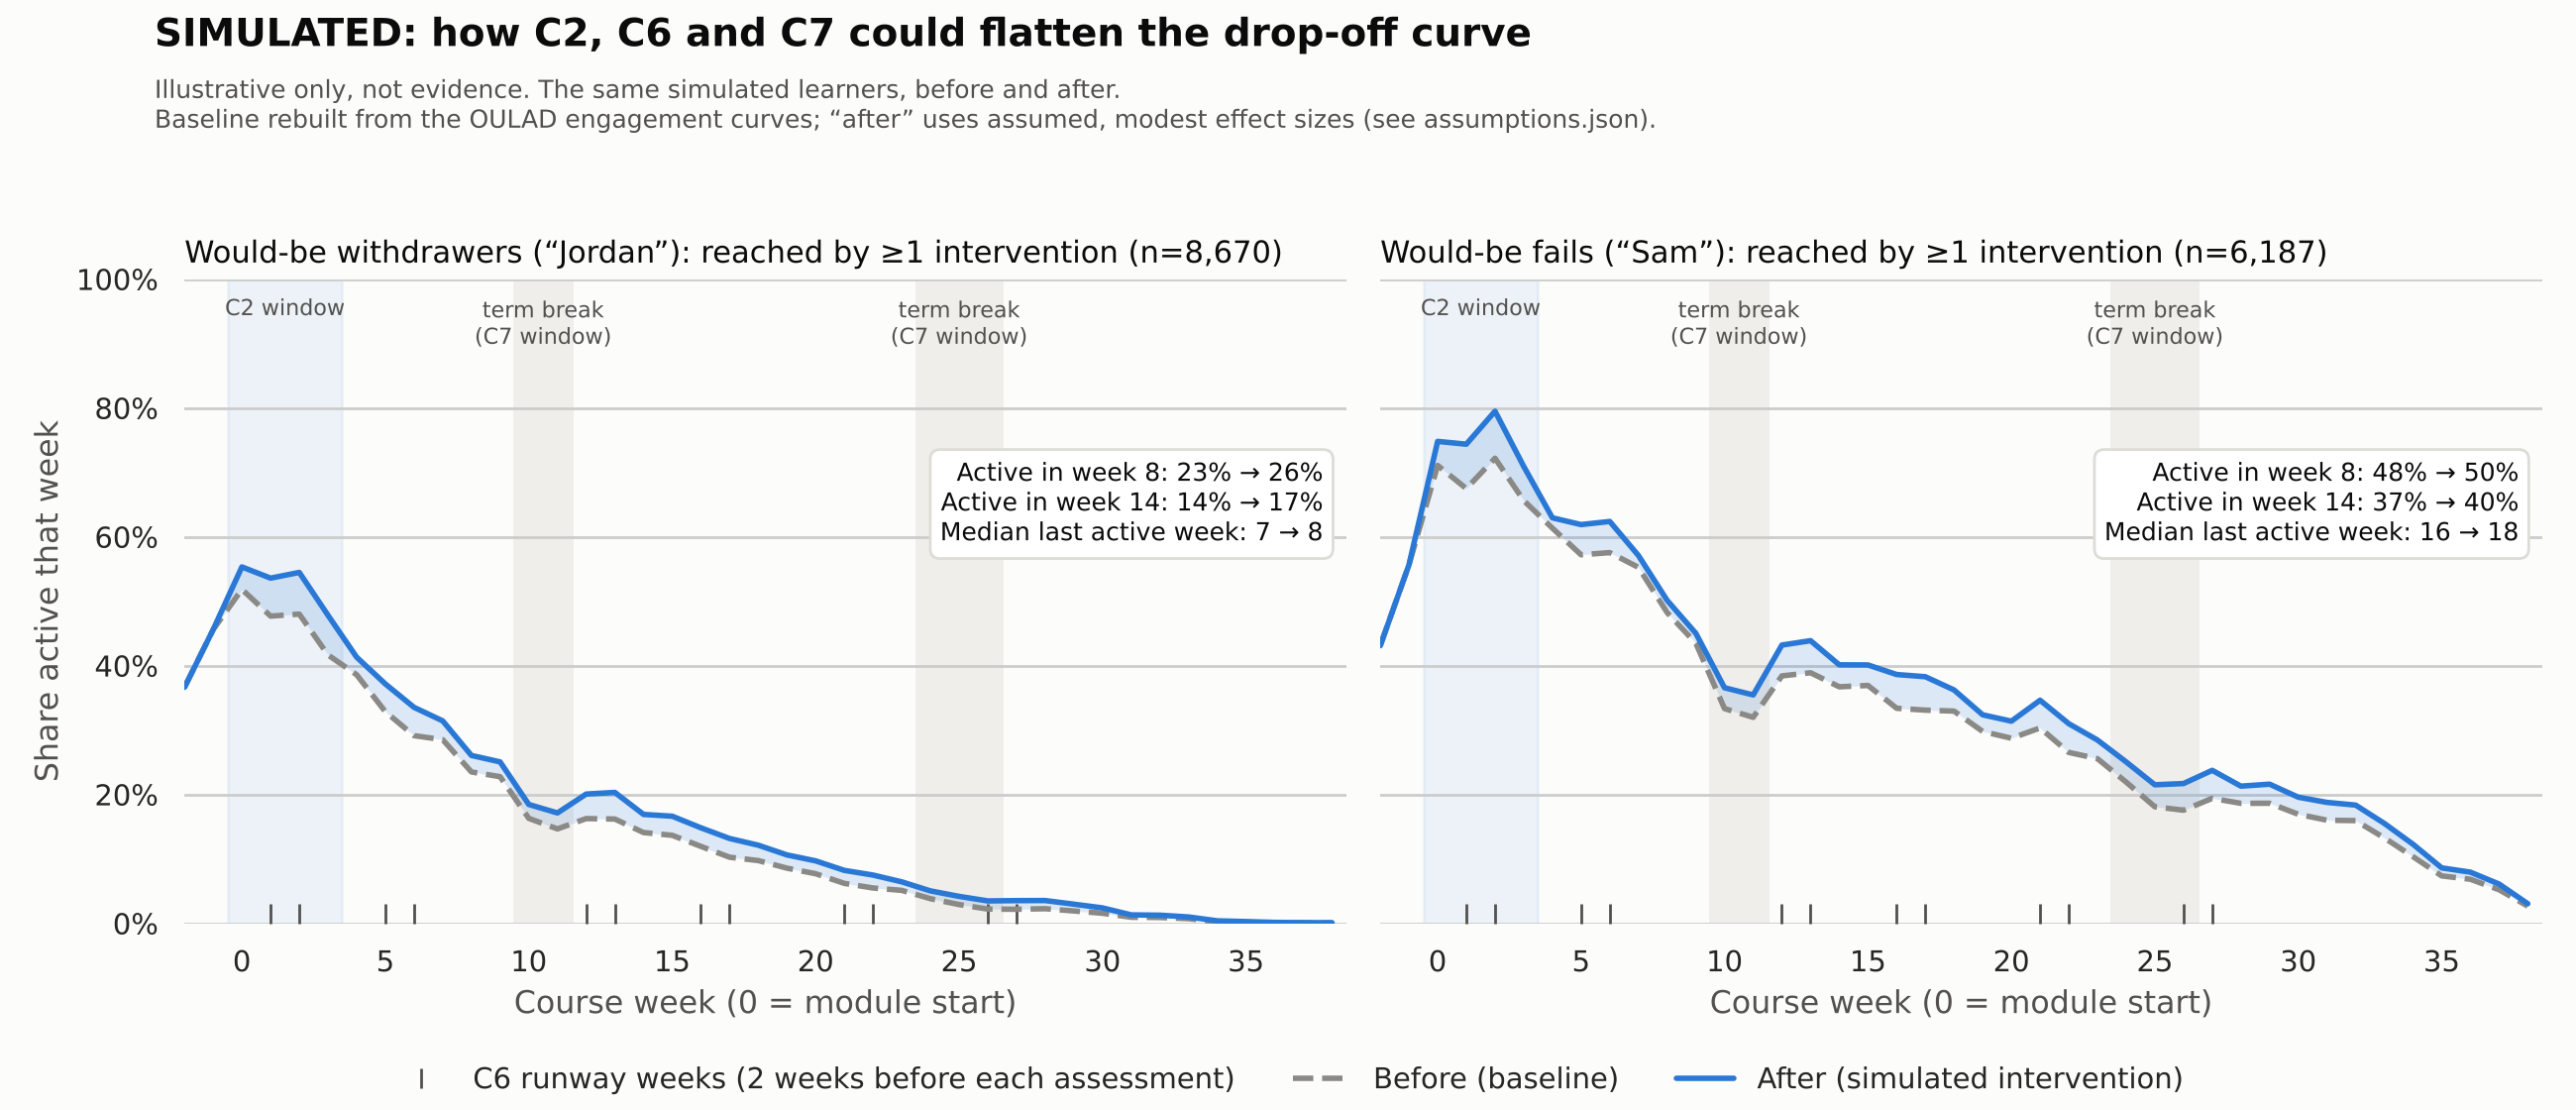

In [15]:
learners, weekly, tma_weeks = sim.simulate()
sim_summary = sim.summarise(learners, weekly)
sim.chart(weekly, tma_weeks, sim_summary, sim.OUT / "before_after_dropoff.png")
sim.chart_all(weekly, sim.OUT / "before_after_all_groups.png")
learners.to_csv(sim.OUT / "simulated_learners_before_after.csv", index=False)
weekly.to_csv(sim.OUT / "simulated_weekly_share_active.csv", index=False)
sim_summary.to_csv(sim.OUT / "simulated_summary.csv", index=False)

print("Assessment weeks used for the C6 runway:", tma_weeks)
display(Image(filename=str(sim.OUT / "before_after_dropoff.png"), width=1000))

In [16]:
cols = {
    "n_reached": "reached",
    "active_wk8_before": "active wk 8, before", "active_wk8_after": "active wk 8, after",
    "active_wk14_before": "active wk 14, before", "active_wk14_after": "active wk 14, after",
    "median_last_active_before": "median last active wk, before",
    "median_last_active_after": "median last active wk, after",
    "projected_pass_rate_points": "projected pass-rate gain (pts)",
}
t = sim_summary.set_index("baseline_result").loc[["Withdrawn", "Fail"], list(cols)].rename(columns=cols)
t.style.format({c: "{:.0%}" for c in t.columns if c.startswith("active")} | {
    "reached": "{:,.0f}", "projected pass-rate gain (pts)": "{:.1f}",
    "median last active wk, before": "{:.0f}", "median last active wk, after": "{:.0f}"})

,reached,"active wk 8, before","active wk 8, after","active wk 14, before","active wk 14, after","median last active wk, before","median last active wk, after",projected pass-rate gain (pts)
baseline_result,,,,,,,,
Withdrawn,"8,670",23%,26%,14%,17%,7,8,0.9
Fail,"6,187",48%,50%,37%,40%,16,18,0.9


**What the simulation says, under its assumptions:** among reached learners, the share of would-be withdrawers still active in week 8 rises by a few points, and the median last active week moves later by about one week for withdrawers and two for students who fail. The implied pass-rate gain is under one point per group. These are small changes by design, since the effect sizes were chosen to be modest.

**What it does not say:** that C2, C6 or C7 would have any effect at all. The effect sizes are guesses, the model treats weekly activity as independent within an engaged spell (so simulated fails stay active a little longer than real ones), and the pass-rate projection stacks two further assumptions (an extra active week ≈ 2 active days, at ≈ 2 points per day). The value of the exercise is that it names exactly which numbers a real pilot with a holdout group would need to measure.

Pass and Distinction curves barely move in the whole-group view (below), as expected, since only C7 reaches them.

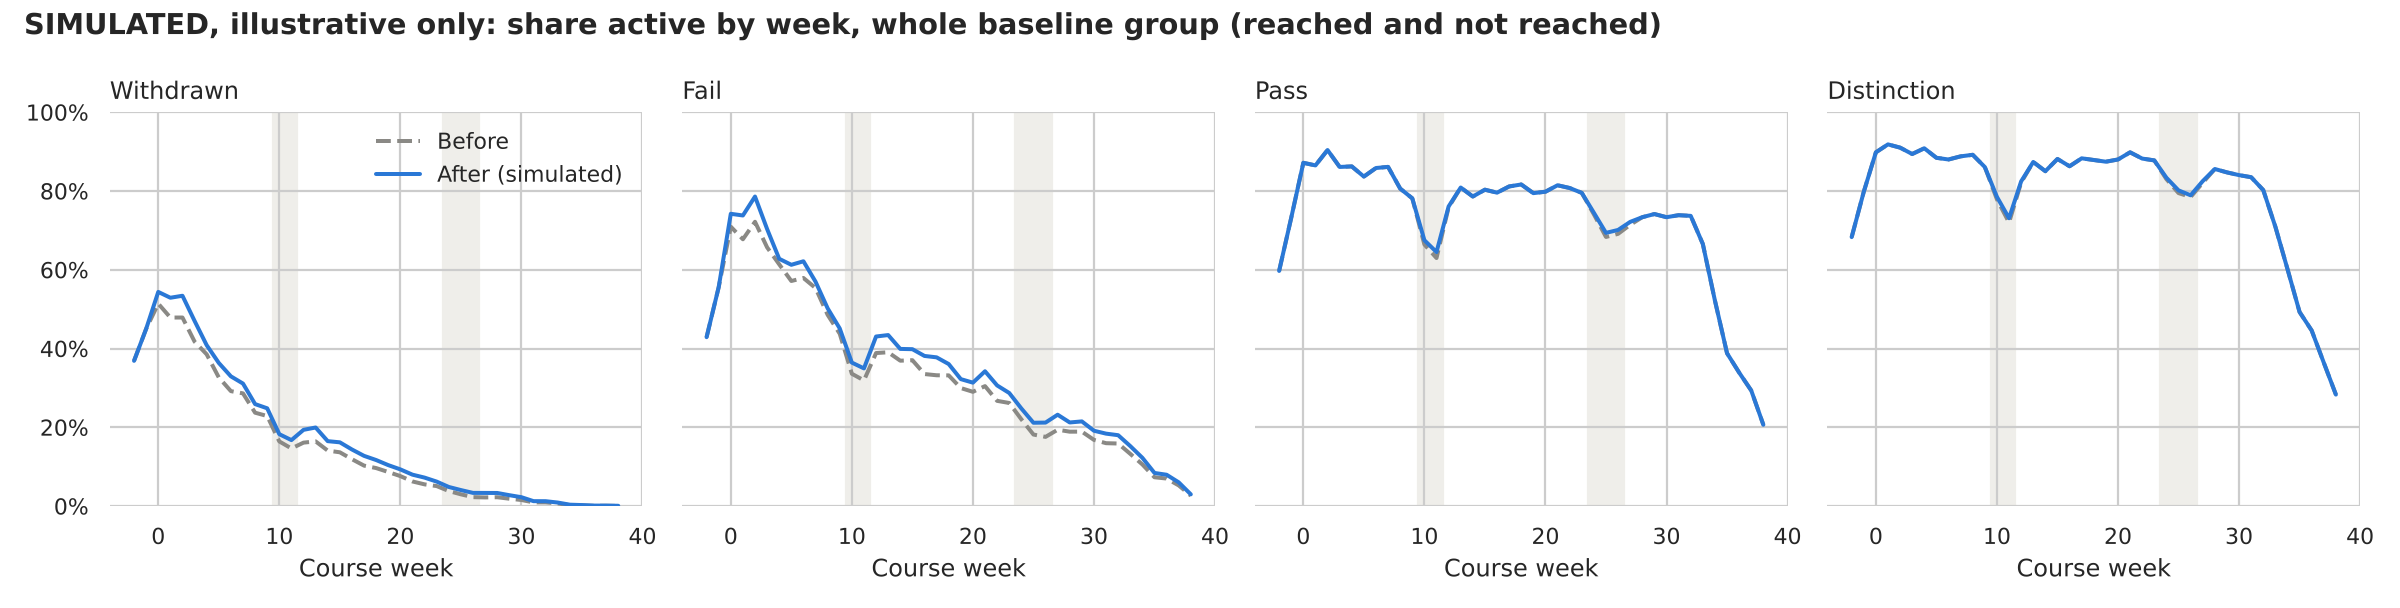

In [17]:
display(Image(filename=str(sim.OUT / "before_after_all_groups.png"), width=1000))

## 10. Limitations and next steps

**Limitations**

- **Proxies.** Clicks and active days stand in for study; they don't measure learning, attention or cognitive load. OULAD has no session timestamps, so "session length" is clicks per active day.
- **Correlation, not causation.** The frequency effect halves within-student, so part of it reflects who the student is. Students who log in more may also differ in motivation, time and support in ways the data can't see.
- **Context.** One institution (the Open University, a distance-learning provider), 7 modules, 2013 to 2014. Patterns may differ for campus or shorter courses.
- **Personas** are built from group-level skews; most withdrawers and faders still look like everyone else on any single attribute. Names, quotes and motives are invented and should be tested with real learners.
- **The simulation is illustrative only** (Section 9).

**Next steps**

1. Replace the assumed effect sizes with ranges from published studies of similar nudges, and show the simulation as a band rather than a single line.
2. Model the drop-off hazard directly (for example a discrete-time survival model on the weekly panel) to test the early-warning signal with proper controls.
3. Run small A/B pilots of C2, C6 and C7 with holdout groups, measuring the outcomes listed in Section 8.
4. Interview or survey learners who match each persona to test the assumed motives.